In [186]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [187]:
df = pd.read_csv("nexlyra_ml_real_estate_1M_ravi.csv",low_memory=False)

In [188]:
df.head()

,Property_ID,Property_Type,Zoning_Code,Country_Code,Square_Footage,Lot_Size_Acres,Year_Built,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Sale_Price,Is_High_Risk
0,PRP-0424009,Single Family,RES-A,US,13532.0,9.686904,1942,12.741211,68.934632,21.0,5,74,C,3.245285e+06,0
1,PRP-0331581,Condo,RES-A,UK,2037.0,2.723955,1953,9.732582,77.078009,NaN,9,54,F,6.300859e+05,0
2,PRP-0021758,Single Family,MIXED,US,11683.0,3.862969,1955,50.584192,1.276102,10.0,9,67,C,3.258259e+06,0
3,PRP-0756056,Single Family,RES-B,DE,927.0,9.104133,1963,87.848449,0.000000,55.0,2,66,E,1.376522e+05,0
4,PRP-0369271,Single Family,RES-B,DE,1133.0,3.524412,1937,6.257245,100.000000,74.0,9,91,B,3.676604e+05,1


In [189]:
df.shape

(1000000, 15)

In [190]:
df.columns

Index(['Property_ID', 'Property_Type', 'Zoning_Code', 'Country_Code',
       'Square_Footage', 'Lot_Size_Acres', 'Year_Built',
       'Distance_To_City_Center_KM', 'Transit_Score', 'Crime_Index',
       'School_District_Rating', 'Environmental_Risk_Score',
       'Energy_Efficiency_Rating', 'Sale_Price', 'Is_High_Risk'],
      dtype='str')

In [191]:
df.dtypes

Property_ID                       str
Property_Type                     str
Zoning_Code                       str
Country_Code                      str
Square_Footage                float64
Lot_Size_Acres                float64
Year_Built                      int64
Distance_To_City_Center_KM    float64
Transit_Score                 float64
Crime_Index                   float64
School_District_Rating          int64
Environmental_Risk_Score        int64
Energy_Efficiency_Rating          str
Sale_Price                    float64
Is_High_Risk                    int64
dtype: object

In [192]:
y_reg = df['Sale_Price']
y_clf = df['Is_High_Risk']
X = df.drop(columns=['Sale_Price','Is_High_Risk'])

In [193]:
from sklearn.model_selection import train_test_split

In [194]:
X_train, X_test, y_train_clf, y_test_clf, y_train_reg,y_test_reg = train_test_split(X, y_clf,y_reg, test_size=0.20, random_state=42, stratify=y_clf)

In [195]:
print((X_train.shape, X_test.shape))

((800000, 13), (200000, 13))


In [196]:
X_train.describe()

,Square_Footage,Lot_Size_Acres,Year_Built,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score
count,760023.000000,800000.000000,800000.000000,800000.000000,800000.000000,736147.000000,800000.000000,800000.000000
mean,7897.569203,5.048886,1971.424465,19.976772,62.865966,49.487409,5.494909,49.563349
std,4100.764833,2.856791,30.065676,19.958934,31.022539,23.068659,2.873375,28.837926
min,800.000000,0.100024,1920.000000,0.000010,0.000000,10.000000,1.000000,0.000000
25%,4341.000000,2.571705,1945.000000,5.752412,43.352552,30.000000,3.000000,25.000000
50%,7900.000000,5.042381,1971.000000,13.868356,71.025251,49.000000,5.000000,50.000000
75%,11458.000000,7.523416,1998.000000,27.715781,88.073639,69.000000,8.000000,75.000000
max,14999.000000,9.999993,2023.000000,278.663810,100.000000,89.000000,10.000000,99.000000


In [197]:
X_train.isnull().sum()

Property_ID                       0
Property_Type                     0
Zoning_Code                       0
Country_Code                      0
Square_Footage                39977
Lot_Size_Acres                    0
Year_Built                        0
Distance_To_City_Center_KM        0
Transit_Score                     0
Crime_Index                   63853
School_District_Rating            0
Environmental_Risk_Score          0
Energy_Efficiency_Rating          0
dtype: int64

In [198]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")

In [199]:
null_value_column = ['Square_Footage','Crime_Index']
X_train[null_value_column] = imputer.fit_transform(X_train[null_value_column])
X_test[null_value_column] = imputer.transform(X_test[null_value_column])

In [200]:
X_train.isnull().sum()

Property_ID                   0
Property_Type                 0
Zoning_Code                   0
Country_Code                  0
Square_Footage                0
Lot_Size_Acres                0
Year_Built                    0
Distance_To_City_Center_KM    0
Transit_Score                 0
Crime_Index                   0
School_District_Rating        0
Environmental_Risk_Score      0
Energy_Efficiency_Rating      0
dtype: int64

In [201]:
X_train['Property_Age'] =  2024 - X_train['Year_Built']
X_test['Property_Age'] =  2024 - X_test['Year_Built']

In [202]:
X_train = X_train.drop(columns='Year_Built')
X_test = X_test.drop(columns='Year_Built')

In [203]:
X_train.head()

,Property_ID,Property_Type,Zoning_Code,Country_Code,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age
695615,PRP-0245247,Condo,RES-B,DE,3205.0,3.073672,22.352499,60.888722,32.0,5,67,F,82
594989,PRP-0563453,Single Family,RES-A,US,14381.0,0.564253,17.490798,70.329559,58.0,1,89,A,101
128940,PRP-0290932,Condo,RES-A,DE,10726.0,4.117354,31.697309,32.345778,43.0,5,75,F,10
591212,PRP-0861392,Single Family,RES-A,US,1963.0,9.649313,34.134510,35.966402,72.0,8,60,C,14
137270,PRP-0278476,Condo,RES-B,US,6247.0,4.553380,3.405350,92.735018,29.0,9,30,C,94


In [204]:
X_test.head()

,Property_ID,Property_Type,Zoning_Code,Country_Code,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age
826338,PRP-0822445,Townhouse,MIXED,UK,3649.0,0.757289,8.197987,87.121074,24.0,9,98,F,81
166426,PRP-0939703,Single Family,RES-A,UK,11071.0,1.621950,0.024821,100.000000,27.0,10,71,C,67
852472,PRP-0151782,Condo,RES-B,UK,7900.0,2.110221,50.063314,0.000000,30.0,9,58,E,19
524790,PRP-0876350,Commercial,COMM,DE,9877.0,1.651674,35.550481,30.186454,56.0,4,17,D,16
736872,PRP-0142713,Condo,RES-A,DE,14350.0,7.065764,38.208412,22.558928,63.0,4,67,F,85


In [205]:
X_train['Transit_to_Distance_Ratio'] = X_train['Transit_Score']/(X_train['Distance_To_City_Center_KM'] + 1)
X_test['Transit_to_Distance_Ratio'] = X_test['Transit_Score']/(X_test['Distance_To_City_Center_KM'] + 1)

In [206]:
X_train.head()

,Property_ID,Property_Type,Zoning_Code,Country_Code,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,Transit_to_Distance_Ratio
695615,PRP-0245247,Condo,RES-B,DE,3205.0,3.073672,22.352499,60.888722,32.0,5,67,F,82,2.607375
594989,PRP-0563453,Single Family,RES-A,US,14381.0,0.564253,17.490798,70.329559,58.0,1,89,A,101,3.803490
128940,PRP-0290932,Condo,RES-A,DE,10726.0,4.117354,31.697309,32.345778,43.0,5,75,F,10,0.989249
591212,PRP-0861392,Single Family,RES-A,US,1963.0,9.649313,34.134510,35.966402,72.0,8,60,C,14,1.023677
137270,PRP-0278476,Condo,RES-B,US,6247.0,4.553380,3.405350,92.735018,29.0,9,30,C,94,21.050546


In [207]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown="ignore",sparse_output=False)

In [208]:
categorical_variable = ['Property_Type', 'Zoning_Code', 'Country_Code']

In [209]:
encoded_X_train = encoder.fit_transform(X_train[categorical_variable])
encoded_X_test = encoder.transform(X_test[categorical_variable])

In [210]:
encoded_X_train = pd.DataFrame(encoded_X_train,columns=encoder.get_feature_names_out(categorical_variable),index=X_train.index)
encoded_X_test = pd.DataFrame(encoded_X_test,columns=encoder.get_feature_names_out(categorical_variable),index=X_test.index)

In [211]:
X_train = pd.concat([X_train.drop(columns=categorical_variable), encoded_X_train],axis=1)
X_test = pd.concat([X_test.drop(columns=categorical_variable), encoded_X_test],axis=1)

In [212]:
X_train.head()

,Property_ID,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
695615,PRP-0245247,3205.0,3.073672,22.352499,60.888722,32.0,5,67,F,82,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
594989,PRP-0563453,14381.0,0.564253,17.490798,70.329559,58.0,1,89,A,101,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
128940,PRP-0290932,10726.0,4.117354,31.697309,32.345778,43.0,5,75,F,10,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
591212,PRP-0861392,1963.0,9.649313,34.134510,35.966402,72.0,8,60,C,14,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
137270,PRP-0278476,6247.0,4.553380,3.405350,92.735018,29.0,9,30,C,94,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [213]:
X_test.head()

,Property_ID,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
826338,PRP-0822445,3649.0,0.757289,8.197987,87.121074,24.0,9,98,F,81,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
166426,PRP-0939703,11071.0,1.621950,0.024821,100.000000,27.0,10,71,C,67,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
852472,PRP-0151782,7900.0,2.110221,50.063314,0.000000,30.0,9,58,E,19,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
524790,PRP-0876350,9877.0,1.651674,35.550481,30.186454,56.0,4,17,D,16,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
736872,PRP-0142713,14350.0,7.065764,38.208412,22.558928,63.0,4,67,F,85,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [217]:
from sklearn.preprocessing import OrdinalEncoder
ordinal_categories = [["F", "E", "D", "C", "B", "A"]]
encoder = OrdinalEncoder(categories=ordinal_categories)

In [218]:
rating = ['Energy_Efficiency_Rating']

In [219]:
X_train[rating] = encoder.fit_transform(X_train[rating])
X_test[rating] = encoder.transform(X_test[rating])

In [220]:
X_train.head()

,Property_ID,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
695615,PRP-0245247,3205.0,3.073672,22.352499,60.888722,32.0,5,67,0.0,82,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
594989,PRP-0563453,14381.0,0.564253,17.490798,70.329559,58.0,1,89,5.0,101,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
128940,PRP-0290932,10726.0,4.117354,31.697309,32.345778,43.0,5,75,0.0,10,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
591212,PRP-0861392,1963.0,9.649313,34.134510,35.966402,72.0,8,60,3.0,14,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
137270,PRP-0278476,6247.0,4.553380,3.405350,92.735018,29.0,9,30,3.0,94,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [221]:
X_test.head()

,Property_ID,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
826338,PRP-0822445,3649.0,0.757289,8.197987,87.121074,24.0,9,98,0.0,81,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
166426,PRP-0939703,11071.0,1.621950,0.024821,100.000000,27.0,10,71,3.0,67,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
852472,PRP-0151782,7900.0,2.110221,50.063314,0.000000,30.0,9,58,1.0,19,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
524790,PRP-0876350,9877.0,1.651674,35.550481,30.186454,56.0,4,17,2.0,16,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
736872,PRP-0142713,14350.0,7.065764,38.208412,22.558928,63.0,4,67,0.0,85,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [222]:
X_train.columns

Index(['Property_ID', 'Square_Footage', 'Lot_Size_Acres',
       'Distance_To_City_Center_KM', 'Transit_Score', 'Crime_Index',
       'School_District_Rating', 'Environmental_Risk_Score',
       'Energy_Efficiency_Rating', 'Property_Age', 'Transit_to_Distance_Ratio',
       'Property_Type_Commercial', 'Property_Type_Condo',
       'Property_Type_Multi-Family', 'Property_Type_Single Family',
       'Property_Type_Townhouse', 'Zoning_Code_COMM', 'Zoning_Code_MIXED',
       'Zoning_Code_RES-A', 'Zoning_Code_RES-B', 'Country_Code_DE',
       'Country_Code_FR', 'Country_Code_IN', 'Country_Code_UK',
       'Country_Code_US'],
      dtype='str')

In [223]:
print((X_train.shape, X_test.shape))

((800000, 25), (200000, 25))


In [224]:
X_train.isnull().sum()

Property_ID                    0
Square_Footage                 0
Lot_Size_Acres                 0
Distance_To_City_Center_KM     0
Transit_Score                  0
Crime_Index                    0
School_District_Rating         0
Environmental_Risk_Score       0
Energy_Efficiency_Rating       0
Property_Age                   0
Transit_to_Distance_Ratio      0
Property_Type_Commercial       0
Property_Type_Condo            0
Property_Type_Multi-Family     0
Property_Type_Single Family    0
Property_Type_Townhouse        0
Zoning_Code_COMM               0
Zoning_Code_MIXED              0
Zoning_Code_RES-A              0
Zoning_Code_RES-B              0
Country_Code_DE                0
Country_Code_FR                0
Country_Code_IN                0
Country_Code_UK                0
Country_Code_US                0
dtype: int64

In [225]:
X_test.isnull().sum()

Property_ID                    0
Square_Footage                 0
Lot_Size_Acres                 0
Distance_To_City_Center_KM     0
Transit_Score                  0
Crime_Index                    0
School_District_Rating         0
Environmental_Risk_Score       0
Energy_Efficiency_Rating       0
Property_Age                   0
Transit_to_Distance_Ratio      0
Property_Type_Commercial       0
Property_Type_Condo            0
Property_Type_Multi-Family     0
Property_Type_Single Family    0
Property_Type_Townhouse        0
Zoning_Code_COMM               0
Zoning_Code_MIXED              0
Zoning_Code_RES-A              0
Zoning_Code_RES-B              0
Country_Code_DE                0
Country_Code_FR                0
Country_Code_IN                0
Country_Code_UK                0
Country_Code_US                0
dtype: int64

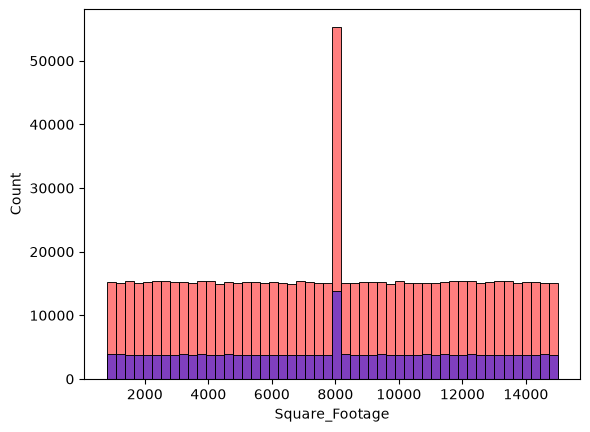

In [226]:
# plotting the graph of prediction and actual values.
sns.histplot( X_train['Square_Footage'], color= 'red', alpha = 0.5, bins= 50)
sns.histplot( X_test['Square_Footage'], color = 'blue', alpha =0.5, bins= 50)
plt.show()

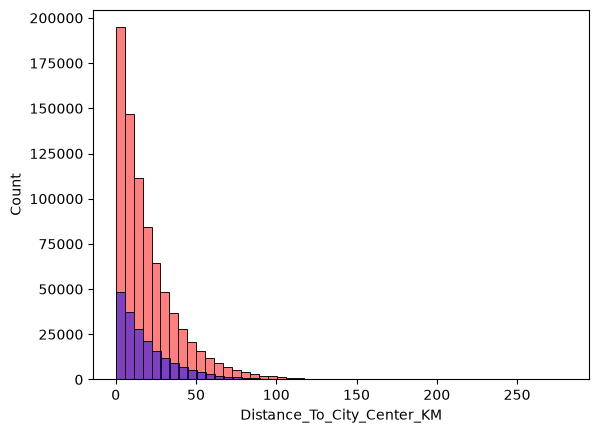

In [227]:
sns.histplot( X_train['Distance_To_City_Center_KM'], color= 'red', alpha = 0.5, bins= 50)
sns.histplot( X_test['Distance_To_City_Center_KM'], color = 'blue', alpha =0.5, bins= 50)
plt.show()

In [228]:
from sklearn.base import BaseEstimator, TransformerMixin

class PercentileCapper(BaseEstimator, TransformerMixin):
    def __init__(self, columns, percentile=0.99):
        self.columns = columns
        self.percentile = percentile

    def fit(self, X, y=None):
        X = X.copy()
        self.upper_limits = {}
        for col in self.columns:
            self.upper_limits[col] = X[col].quantile(self.percentile)
        return self

    def transform(self, X):
        X = X.copy()
        for col in self.columns:
            X[col] = X[col].clip(upper=self.upper_limits[col])
        return X

In [229]:
capper = PercentileCapper(columns=['Square_Footage'],percentile=0.99)
X_train = capper.fit_transform(X_train)
X_test = capper.transform(X_test)

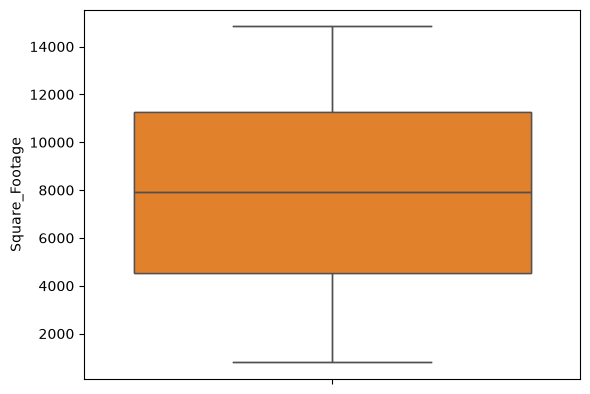

In [230]:
sns.boxplot(X_train['Square_Footage'])
sns.boxplot(X_test['Square_Footage'])
plt.show()

In [231]:
from sklearn.preprocessing import PowerTransformer
pt = PowerTransformer(method="yeo-johnson")

In [232]:
skewed_features = ['Distance_To_City_Center_KM']
X_train[skewed_features] = pt.fit_transform(X_train[skewed_features])
X_test[skewed_features] = pt.transform(X_test[skewed_features])

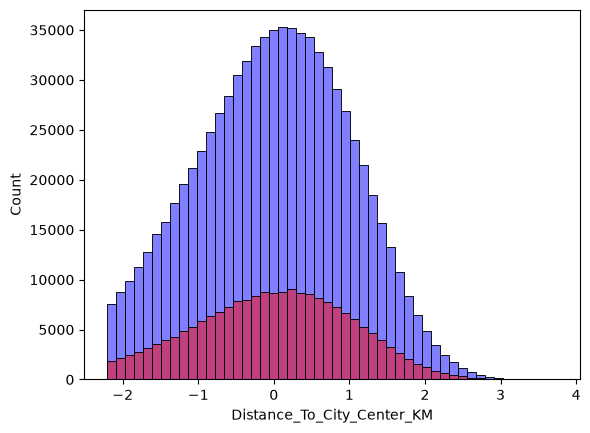

In [233]:
sns.histplot( X_train['Distance_To_City_Center_KM'], color = 'blue', alpha =0.5, bins= 50)
sns.histplot( X_test['Distance_To_City_Center_KM'], color= 'red', alpha = 0.5, bins= 50)
plt.show()

In [234]:
X_train.nunique().sort_values()

Property_Type_Condo                 2
Property_Type_Multi-Family          2
Property_Type_Single Family         2
Property_Type_Townhouse             2
Property_Type_Commercial            2
Zoning_Code_RES-A                   2
Zoning_Code_MIXED                   2
Country_Code_US                     2
Country_Code_UK                     2
Country_Code_IN                     2
Country_Code_FR                     2
Country_Code_DE                     2
Zoning_Code_RES-B                   2
Zoning_Code_COMM                    2
Energy_Efficiency_Rating            6
School_District_Rating             10
Crime_Index                        80
Environmental_Risk_Score          100
Property_Age                      104
Square_Footage                  14047
Transit_Score                  663837
Transit_to_Distance_Ratio      732775
Lot_Size_Acres                 800000
Distance_To_City_Center_KM     800000
Property_ID                    800000
dtype: int64

In [235]:
X_train.head()

,Property_ID,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
695615,PRP-0245247,3205.0,3.073672,0.500187,60.888722,32.0,5,67,0.0,82,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
594989,PRP-0563453,14381.0,0.564253,0.252736,70.329559,58.0,1,89,5.0,101,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
128940,PRP-0290932,10726.0,4.117354,0.872535,32.345778,43.0,5,75,0.0,10,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
591212,PRP-0861392,1963.0,9.649313,0.954521,35.966402,72.0,8,60,3.0,14,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
137270,PRP-0278476,6247.0,4.553380,-1.092221,92.735018,29.0,9,30,3.0,94,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [236]:
continious_variable = ['Lot_Size_Acres','Distance_To_City_Center_KM','Transit_to_Distance_Ratio',
                       'Transit_Score','Square_Footage','Property_Age','Environmental_Risk_Score','Crime_Index']

In [237]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [238]:
X_train[continious_variable] = scaler.fit_transform(X_train[continious_variable])
X_test[continious_variable] = scaler.transform(X_test[continious_variable])

In [239]:
print((X_train.shape, X_test.shape))

((800000, 25), (200000, 25))


In [240]:
X_train.head()

,Property_ID,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
695615,PRP-0245247,-1.174258,-0.691410,0.500187,-0.063736,-0.788481,5,0.604643,0.0,0.978674,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
594989,PRP-0563453,1.622780,-1.569816,0.252736,0.240586,0.386434,1,1.367528,5.0,1.610624,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
128940,PRP-0290932,0.708037,-0.326077,0.872535,-0.983808,-0.291402,5,0.882056,0.0,-1.416085,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
591212,PRP-0861392,-1.485095,1.610348,0.954521,-0.867098,1.019080,8,0.361907,3.0,-1.283043,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
137270,PRP-0278476,-0.412931,-0.173449,-1.092221,0.962818,-0.924048,9,-0.678390,3.0,1.377800,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [241]:
import numpy as np

In [242]:
X_train_np = X_train.to_numpy()
X_test_np = X_test.to_numpy()

print(f"X_train: {X_train_np.nbytes / 1024**2:.2f} MB")
print(f"X_test: {X_test_np.nbytes / 1024**2:.2f} MB")

X_train: 152.59 MB
X_test: 38.15 MB


In [243]:
print(f'Shape of X_train {X_train.dtypes}')

Shape of X_train Property_ID                        str
Square_Footage                 float64
Lot_Size_Acres                 float64
Distance_To_City_Center_KM     float64
Transit_Score                  float64
Crime_Index                    float64
School_District_Rating           int64
Environmental_Risk_Score       float64
Energy_Efficiency_Rating       float64
Property_Age                   float64
Transit_to_Distance_Ratio      float64
Property_Type_Commercial       float64
Property_Type_Condo            float64
Property_Type_Multi-Family     float64
Property_Type_Single Family    float64
Property_Type_Townhouse        float64
Zoning_Code_COMM               float64
Zoning_Code_MIXED              float64
Zoning_Code_RES-A              float64
Zoning_Code_RES-B              float64
Country_Code_DE                float64
Country_Code_FR                float64
Country_Code_IN                float64
Country_Code_UK                float64
Country_Code_US                float64
dtype: o

In [244]:
print(f'Shape of X_test {X_test.dtypes}')

Shape of X_test Property_ID                        str
Square_Footage                 float64
Lot_Size_Acres                 float64
Distance_To_City_Center_KM     float64
Transit_Score                  float64
Crime_Index                    float64
School_District_Rating           int64
Environmental_Risk_Score       float64
Energy_Efficiency_Rating       float64
Property_Age                   float64
Transit_to_Distance_Ratio      float64
Property_Type_Commercial       float64
Property_Type_Condo            float64
Property_Type_Multi-Family     float64
Property_Type_Single Family    float64
Property_Type_Townhouse        float64
Zoning_Code_COMM               float64
Zoning_Code_MIXED              float64
Zoning_Code_RES-A              float64
Zoning_Code_RES-B              float64
Country_Code_DE                float64
Country_Code_FR                float64
Country_Code_IN                float64
Country_Code_UK                float64
Country_Code_US                float64
dtype: ob

In [245]:
X_train = X_train.drop(columns='Property_ID')
X_test = X_test.drop(columns='Property_ID')

In [246]:
X_train.head()

,Square_Footage,Lot_Size_Acres,Distance_To_City_Center_KM,Transit_Score,Crime_Index,School_District_Rating,Environmental_Risk_Score,Energy_Efficiency_Rating,Property_Age,Transit_to_Distance_Ratio,...,Property_Type_Townhouse,Zoning_Code_COMM,Zoning_Code_MIXED,Zoning_Code_RES-A,Zoning_Code_RES-B,Country_Code_DE,Country_Code_FR,Country_Code_IN,Country_Code_UK,Country_Code_US
695615,-1.174258,-0.691410,0.500187,-0.063736,-0.788481,5,0.604643,0.0,0.978674,-0.523660,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
594989,1.622780,-1.569816,0.252736,0.240586,0.386434,1,1.367528,5.0,1.610624,-0.449545,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
128940,0.708037,-0.326077,0.872535,-0.983808,-0.291402,5,0.882056,0.0,-1.416085,-0.623923,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
591212,-1.485095,1.610348,0.954521,-0.867098,1.019080,8,0.361907,3.0,-1.283043,-0.621790,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
137270,-0.412931,-0.173449,-1.092221,0.962818,-0.924048,9,-0.678390,3.0,1.377800,0.619132,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [247]:
float_cols = X_train.select_dtypes(include="float64").columns

In [248]:
X_train[float_cols] = X_train[float_cols].astype("float32")
X_test[float_cols] = X_test[float_cols].astype("float32")

In [249]:
X_train_after = X_train.to_numpy(dtype=np.float32)
X_test_after = X_test.to_numpy(dtype=np.float32)

In [250]:
print(f"X_train: {X_train_after.nbytes / 1024**2:.2f} MB")
print(f"X_test: {X_test_after.nbytes / 1024**2:.2f} MB")

X_train: 73.24 MB
X_test: 18.31 MB


In [251]:
print(f"X_train before downcaste: {X_train_np.nbytes / 1024**2:.2f} MB")
print(f"X_test before downcaste: {X_test_np.nbytes / 1024**2:.2f} MB")

print(f"X_train after downcaste: {X_train_after.nbytes / 1024**2:.2f} MB")
print(f"X_test after downcaste: {X_test_after.nbytes / 1024**2:.2f} MB")

X_train before downcaste: 152.59 MB
X_test before downcaste: 38.15 MB
X_train after downcaste: 73.24 MB
X_test after downcaste: 18.31 MB


In [252]:
print(f"Shape of X_train : {X_train.shape}, Shape of y_train: {y_train.shape}")

Shape of X_train : (800000, 24), Shape of y_train: (800000,)


In [254]:
X_train.dtypes

Square_Footage                 float32
Lot_Size_Acres                 float32
Distance_To_City_Center_KM     float32
Transit_Score                  float32
Crime_Index                    float32
School_District_Rating           int64
Environmental_Risk_Score       float32
Energy_Efficiency_Rating       float32
Property_Age                   float32
Transit_to_Distance_Ratio      float32
Property_Type_Commercial       float32
Property_Type_Condo            float32
Property_Type_Multi-Family     float32
Property_Type_Single Family    float32
Property_Type_Townhouse        float32
Zoning_Code_COMM               float32
Zoning_Code_MIXED              float32
Zoning_Code_RES-A              float32
Zoning_Code_RES-B              float32
Country_Code_DE                float32
Country_Code_FR                float32
Country_Code_IN                float32
Country_Code_UK                float32
Country_Code_US                float32
dtype: object

In [255]:
X_train_np = X_train.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

y_train_clf_np = y_train_clf.to_numpy()
y_test_clf_np = y_test_clf.to_numpy()

y_train_reg_np = y_train_reg.to_numpy()
y_test_reg_np = y_test_reg.to_numpy()

In [256]:
# Save arrays
np.save("X_train.npy", X_train_np)
np.save("X_test.npy", X_test_np)

np.save("y_train_clf.npy", y_train_clf_np)
np.save("y_test_clf.npy", y_test_clf_np)

np.save("y_train_reg.npy", y_train_reg_np)
np.save("y_test_reg.npy", y_test_reg_np)